> Note: This notebook has been superseded by `notebooks/concepts_age_unified.ipynb` (single place for both AoA-lexicon and story-age concept distributions).


# AoA + Word2Vec concept analysis (lemma space)

Goal: train a simple Word2Vec embedding over **review event text** (from `review_samples`) and use the **AoA lexicon (lemma form)** to surface human-interpretable clusters / “concepts” that differ by age bin (`0–3`, `4–6`, `7–12`).

This is a *separate* analysis from the activation probes: it’s a transparent distributional baseline to interpret what kinds of content/semantics appear in different age groups.


In [1]:
import os
os.chdir('/Users/tzl/repos/story-features')
print('cwd:', os.getcwd())


cwd: /Users/tzl/repos/story-features


In [2]:
from __future__ import annotations

import json
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


## Load master + build event text

We use the event segmentation from `review_samples` via `review_events_json` (already merged into the master by `scripts/build_master_dataset.py`).


In [3]:
def read_master() -> tuple[Path, pd.DataFrame]:
    candidates = [
        Path('data/processed/master_batch1.csv.gz'),
        Path('data/processed/master_batch1.parquet'),
        Path('data/processed/master_stories.csv.gz'),
        Path('data/processed/master_stories.parquet'),
    ]
    p = next((x for x in candidates if x.exists()), None)
    if p is None:
        raise FileNotFoundError('No master found under data/processed/')
    if p.suffix == '.parquet':
        df = pd.read_parquet(p)
    else:
        df = pd.read_csv(p, low_memory=False)
    return p, df


path, master = read_master()
print('Loaded:', path, master.shape)
master[['video_id','story_id','Reading Age','age_mid']].head(3)


Loaded: data/processed/master_batch1.csv.gz (2860, 551)


,video_id,story_id,Reading Age,age_mid
0,HLJgZlQbtCE,NaN,"6 - 10 years, from customers",8.0
1,KX0KnaVuWTE,NaN,8 - 12 years,10.0
2,ekjCeiImCzE,NaN,4 - 12 years,8.0


In [4]:
def _safe_json_loads(x):
    if x is None:
        return None
    if isinstance(x, float) and np.isnan(x):
        return None
    if isinstance(x, (dict, list)):
        return x
    s = str(x).strip()
    if not s or s.lower() == 'nan':
        return None
    try:
        return json.loads(s)
    except Exception:
        return None


def iter_event_texts(review_events_json):
    events = _safe_json_loads(review_events_json)
    if not isinstance(events, list):
        return
    for e in events:
        if not isinstance(e, dict):
            continue
        sents = e.get('sentences')
        if not isinstance(sents, list):
            continue
        parts = []
        for s in sents:
            if isinstance(s, dict) and 'text' in s:
                parts.append(str(s['text']))
            elif isinstance(s, str):
                parts.append(s)
        txt = ' '.join(p.strip() for p in parts if p and str(p).strip()).strip()
        if txt:
            yield txt


work = master.copy()
work['age_mid'] = pd.to_numeric(work.get('age_mid'), errors='coerce')
work = work[(work['age_mid'].notna()) & (work.get('review_events_json').notna())].copy()
print('rows w/ age_mid & review_events_json:', len(work))


rows w/ age_mid & review_events_json: 333


## Define age bins


In [5]:
def age_bin(age_mid: float) -> str:
    if age_mid <= 3:
        return '0-3'
    if age_mid <= 6:
        return '4-6'
    return '7-12'


work['age_bin'] = work['age_mid'].apply(age_bin)
work['age_bin'].value_counts()


age_bin
4-6     234
7-12     64
0-3      35
Name: count, dtype: int64

## Load AoA lexicon (lemma column)

We prefer `data/aoa/AoA_51715_words.xlsx` and use the lemma-based AoA column when present (commonly `AoA_Kup_lem`).


In [6]:
def load_aoa_lexicon() -> tuple[Path, pd.DataFrame]:
    candidates = [
        Path('data/aoa/AoA_51715_words.xlsx'),
        Path('data/aoa/AoA_51715_words.csv'),
        Path('data/aoa/AoA_ratings_Kuperman_et_al_BRM_with_PoS.xlsx'),
    ]
    p = next((x for x in candidates if x.exists()), None)
    if p is None:
        raise FileNotFoundError('No AoA lexicon found under data/aoa/')
    if p.suffix in {'.xlsx', '.xls'}:
        df = pd.read_excel(p)
    else:
        df = pd.read_csv(p, low_memory=False)
    return p, df


aoa_path, aoa_df = load_aoa_lexicon()
print('AoA loaded:', aoa_path, aoa_df.shape)
aoa_df.columns[:20]


AoA loaded: data/aoa/AoA_51715_words.xlsx (51715, 16)


Index(['Word', 'Alternative.spelling', 'Freq_pm', 'Dom_PoS_SUBTLEX',
       'Nletters', 'Nphon', 'Nsyll', 'Lemma_highest_PoS', 'AoA_Kup',
       'Perc_known', 'AoA_Kup_lem', 'Perc_known_lem', 'AoA_Bird_lem',
       'AoA_Bristol_lem', 'AoA_Cort_lem', 'AoA_Schock'],
      dtype='object')

In [7]:
def guess_cols(df: pd.DataFrame) -> tuple[str, str]:
    cols = list(df.columns)
    # word column
    word_candidates = [c for c in cols if str(c).lower() in {'word', 'wordform', 'lemma'}]
    word_col = word_candidates[0] if word_candidates else cols[0]
    # age column preference order
    age_pref = ['aoa_kup_lem', 'aoa_kup', 'rating.mean', 'rating_mean', 'aoa']
    age_col = None
    for want in age_pref:
        for c in cols:
            if str(c).strip().lower() == want:
                age_col = c
                break
        if age_col:
            break
    if age_col is None:
        # last resort: first numeric-ish col
        for c in cols:
            if pd.to_numeric(df[c], errors='coerce').notna().any():
                age_col = c
                break
    if age_col is None:
        raise ValueError('Could not infer AoA age column')
    return word_col, age_col


word_col, age_col = guess_cols(aoa_df)
print('Using word_col:', word_col)
print('Using age_col: ', age_col)

tmp = aoa_df[[word_col, age_col]].copy()
tmp[word_col] = tmp[word_col].astype(str).str.lower().str.strip()
tmp[age_col] = pd.to_numeric(tmp[age_col], errors='coerce')
tmp = tmp[tmp[word_col].str.match(r'^[a-z]+$') & tmp[age_col].notna()].drop_duplicates(subset=[word_col])
aoa = dict(zip(tmp[word_col].tolist(), tmp[age_col].tolist()))
print('AoA entries:', len(aoa), 'example:', list(aoa.items())[:5])


Using word_col: Word
Using age_col:  AoA_Kup_lem
AoA entries: 51694 example: [('a', 2.8933839999999993), ('aardvark', 9.89), ('abacus', 8.69), ('abacuses', 8.69), ('abalone', 12.23)]


## Lemmatization

We try spaCy if available; otherwise fall back to a small heuristic lemmatizer.

Recommended local deps:

```
pip install gensim spacy scikit-learn
python -m spacy download en_core_web_sm
pip install umap-learn  # optional
```


In [8]:
WORD_RE = re.compile(r"[A-Za-z']+")

try:
    import spacy
    _nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
    def lemmatize(text: str) -> list[str]:
        doc = _nlp(text)
        out=[]
        for t in doc:
            if not t.is_alpha:
                continue
            if t.is_stop:
                continue
            lem = (t.lemma_ or '').lower().strip()
            if lem and lem != '-pron-':
                out.append(lem)
        return out
    print('Using spaCy lemmatizer')
except Exception as e:
    def _lemma_heuristic(w: str) -> str:
        w = w.lower().strip("'")
        # very small set of rules; keeps other analyses separate/unchanged
        for suf in ['ing','ed','ies','s']:
            if len(w) > 4 and w.endswith(suf):
                if suf == 'ies':
                    return w[:-3] + 'y'
                if suf == 's':
                    return w[:-1]
                return w[:-len(suf)]
        return w

    def lemmatize(text: str) -> list[str]:
        toks = [t.lower() for t in WORD_RE.findall(text)]
        toks = [t for t in toks if len(t) >= 2]
        return [_lemma_heuristic(t) for t in toks]

    print('Using heuristic lemmatizer:', repr(e)[:200])


Using heuristic lemmatizer: ModuleNotFoundError("No module named 'spacy'")


## Build event-level “sentences” for Word2Vec

Each event is treated as one sentence (list of lemmas). This respects event boundaries.


In [9]:
sentences = []
sent_meta = []

for row in work.itertuples(index=False):
    evs = list(iter_event_texts(getattr(row, 'review_events_json')))
    for ev_i, ev_txt in enumerate(evs):
        toks = lemmatize(ev_txt)
        if len(toks) < 5:
            continue
        sentences.append(toks)
        sent_meta.append({
            'item_id': getattr(row, 'video_id', None),
            'story_id': getattr(row, 'story_id', None),
            'age_mid': float(getattr(row, 'age_mid')),
            'age_bin': getattr(row, 'age_bin'),
            'event': ev_i,
        })

print('event sentences:', len(sentences))
print('example:', sentences[0][:30])


event sentences: 3542
example: ['there', 'is', 'letter', 'address', 'to', 'emile', "he's", 'been', 'invit', 'to', 'attend', 'the', 'meet', 'of', 'the', 'night', 'creature', 'to', 'hear', 'very', 'important', 'announcement', 'the', 'night', 'creature', 'have', 'chosen', 'him', 'as', 'the']


## Train Word2Vec


In [10]:
from gensim.models import Word2Vec

# You can tweak these; keep min_count > 1 to reduce noise.
w2v = Word2Vec(
    sentences=sentences,
    vector_size=200,
    window=6,
    min_count=5,
    sg=1,
    negative=10,
    epochs=10,
    workers=max(1, os.cpu_count() - 1),
    seed=0,
)

print('vocab size:', len(w2v.wv))


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


vocab size: 3800


## Continuous age map (no bins)

Two views:
1) Project **story/event embeddings** and color by `age_mid` to see a smooth gradient.
2) Fit a linear **age direction** in embedding space (ridge regression) and rank words by their projection onto that direction for interpretability.


In [11]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

def mean_vec(tokens):
    toks = [t for t in tokens if t in w2v.wv]
    if not toks:
        return None
    X = np.vstack([w2v.wv[t] for t in toks])
    return X.mean(axis=0)

# Build event vectors
event_vecs = []
event_meta = []
for i, m in enumerate(sent_meta):
    v = mean_vec(sentences[i])
    if v is None:
        continue
    event_vecs.append(v)
    event_meta.append(m)

event_meta_df = pd.DataFrame(event_meta)
event_X = np.vstack(event_vecs)
print('event vectors:', event_X.shape)
event_meta_df.head(3)


event vectors: (3542, 200)


,item_id,story_id,age_mid,age_bin,event
0,T7nVgn9qBJs,10265.0,6.0,4-6,0
1,T7nVgn9qBJs,10265.0,6.0,4-6,1
2,T7nVgn9qBJs,10265.0,6.0,4-6,2


In [12]:
# Aggregate to story vectors (mean over events per story_id)
tmp = event_meta_df.copy()
tmp['i'] = np.arange(len(tmp))
story_rows = []
for sid, g in tmp.groupby('story_id'):
    idx = g['i'].to_numpy()
    v = event_X[idx].mean(axis=0)
    story_rows.append({
        "story_id": sid,
        "age_mid": float(g['age_mid'].iloc[0]),
        "n_events_used": int(len(g)),
        "vec": v,
    })

story_df = pd.DataFrame(story_rows)
story_X = np.vstack(story_df['vec'].to_numpy())
story_y = story_df['age_mid'].to_numpy()
print('story vectors:', story_X.shape, "age_mid range", (float(np.min(story_y)), float(np.max(story_y))))
story_df.head(3)


story vectors: (330, 200) age_mid range (2.0, 10.5)


,story_id,age_mid,n_events_used,vec
0,552.0,3.5,9,"[0.06599262, 0.018151484, -0.17152163, -0.2643..."
1,791.0,6.0,15,"[0.09776299, -0.020288259, -0.18213582, -0.213..."
2,801.0,5.0,6,"[0.09445062, -0.007062239, -0.19110616, -0.162..."


/opt/anaconda3/envs/story-features/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


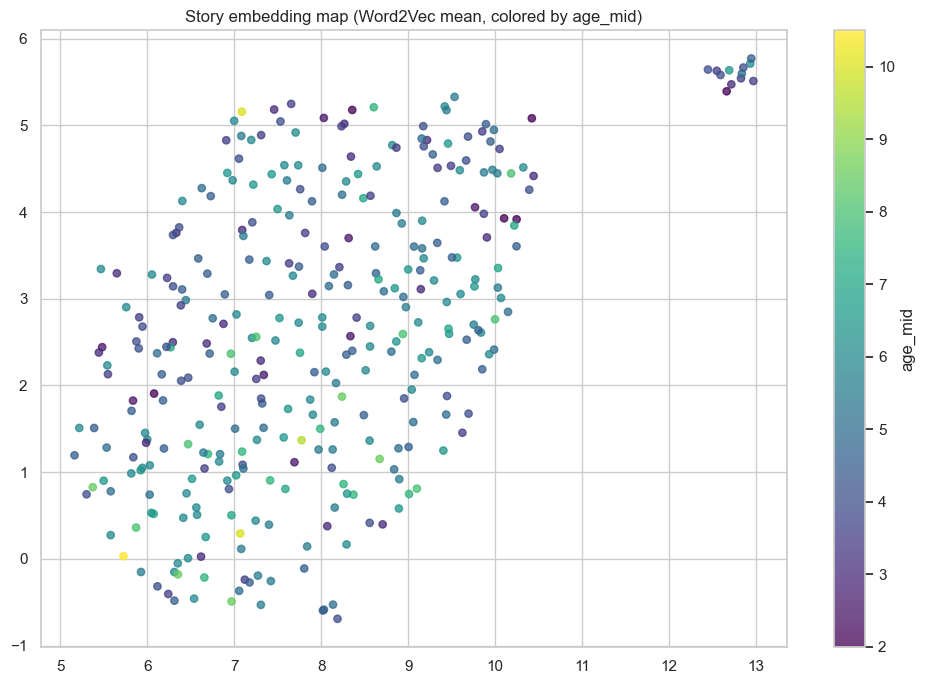

In [13]:
def embed_2d(X: np.ndarray) -> np.ndarray:
    try:
        import umap
        return umap.UMAP(n_neighbors=25, min_dist=0.25, random_state=0).fit_transform(X)
    except Exception:
        from sklearn.decomposition import PCA
        return PCA(n_components=2, random_state=0).fit_transform(X)

xy = embed_2d(story_X)
viz = story_df[['story_id','age_mid','n_events_used']].copy()
viz['x'] = xy[:,0]
viz['y'] = xy[:,1]

plt.figure(figsize=(10,7))
sc = plt.scatter(viz['x'], viz['y'], c=viz['age_mid'], cmap='viridis', s=28, alpha=0.75)
plt.colorbar(sc, label='age_mid')
plt.title('Story embedding map (Word2Vec mean, colored by age_mid)')
plt.tight_layout()


In [14]:
# Fit an age direction in embedding space
scaler = StandardScaler(with_mean=True, with_std=True)
Xz = scaler.fit_transform(story_X)
ridge = Ridge(alpha=10.0, random_state=0)
ridge.fit(Xz, story_y)
w = ridge.coef_.astype(np.float64)
w = w / (np.linalg.norm(w) + 1e-12)

# Score words by projection on the learned age direction
rows=[]
for word in w2v.wv.index_to_key:
    v = w2v.wv[word].astype(np.float64)
    # match scaling used for story vectors: center/scale each dim
    v_z = (v - scaler.mean_) / (scaler.scale_ + 1e-12)
    score = float(np.dot(w, v_z))
    rows.append({
        "word": word,
        "age_axis_score": score,
        "aoa": aoa.get(word, np.nan),
        "count": sum(counts[b].get(word, 0) for b in ["0-3","4-6","7-12"])
    })
word_scores = pd.DataFrame(rows)

print('Top words (older direction):')
display(word_scores.sort_values('age_axis_score', ascending=False).head(25))
print('Top words (younger direction):')
display(word_scores.sort_values('age_axis_score', ascending=True).head(25))


NameError: name 'counts' is not defined

## BERT (CPU) story embedding map (optional)

This repeats the *continuous age map* idea, but uses a small BERT-family encoder on CPU. It is slower than Word2Vec.

- Uses `distilbert-base-uncased` by default (change `MODEL_NAME`).
- Embedding = mean pooled last hidden state (excluding special tokens), per event; story embedding = mean over events.
- Truncates each event to `MAX_LEN` wordpieces.

If `torch/transformers` are not installed locally, install them first (CPU is fine).


In [16]:
MODEL_NAME = 'distilbert-base-uncased'
MAX_LEN = 256
BATCH_SIZE = 16
CACHE_PATH = Path('artifacts/aoa_word2vec/bert_story_embeddings_distilbert.csv')
CACHE_PATH


PosixPath('artifacts/aoa_word2vec/bert_story_embeddings_distilbert.csv')

In [17]:
# torch is only needed for the BERT section
try:
    import torch
except Exception as e:
    print('torch not available:', e)


In [18]:
def mean_pool_last_hidden(last_hidden, attention_mask):
    # last_hidden: (B, T, H), attention_mask: (B, T)
    m = attention_mask.unsqueeze(-1).to(last_hidden.dtype)
    # drop [CLS] at 0
    if last_hidden.shape[1] >= 1:
        m[:,0,:] = 0
    # drop [SEP] (last attended token)
    lengths = attention_mask.long().sum(dim=1).clamp(min=1)
    sep_idx = (lengths - 1).clamp(min=0)
    m[torch.arange(last_hidden.shape[0]), sep_idx, :] = 0
    denom = m.sum(dim=1).clamp(min=1e-6)
    return (last_hidden * m).sum(dim=1) / denom


In [19]:
if CACHE_PATH.exists():
    bert_df = pd.read_csv(CACHE_PATH, low_memory=False)
    print('Loaded cache:', CACHE_PATH, bert_df.shape)
else:
    import torch
    from transformers import AutoModel, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    mdl = AutoModel.from_pretrained(MODEL_NAME)
    mdl.eval()
    device = torch.device('cpu')
    mdl.to(device)

    # Build a stable story list from the same `work` used above
    rows = []
    for r in work.itertuples(index=False):
        story_id = getattr(r, 'story_id', None)
        age = float(getattr(r, 'age_mid'))
        ev_texts = list(iter_event_texts(getattr(r, 'review_events_json')))
        if not ev_texts:
            continue
        rows.append((story_id, age, ev_texts))

    print('stories for bert:', len(rows))

    out_rows = []
    with torch.no_grad():
        for si, (sid, age, ev_texts) in enumerate(rows):
            # embed events in batches
            ev_vecs = []
            for start in range(0, len(ev_texts), BATCH_SIZE):
                batch = ev_texts[start:start+BATCH_SIZE]
                enc = tok(batch, return_tensors='pt', padding=True, truncation=True, max_length=MAX_LEN)
                enc = {k: v.to(device) for k,v in enc.items()}
                out = mdl(**enc)
                pooled = mean_pool_last_hidden(out.last_hidden_state, enc['attention_mask'])
                ev_vecs.append(pooled.cpu().numpy())
            ev_mat = np.vstack(ev_vecs)
            story_vec = ev_mat.mean(axis=0)
            rec = {'story_id': sid, 'age_mid': age, 'n_events': len(ev_texts)}
            for j, val in enumerate(story_vec.tolist()):
                rec[f'd{j}'] = float(val)
            out_rows.append(rec)
            if (si+1) % 25 == 0:
                print('embedded', si+1, '/', len(rows))

    bert_df = pd.DataFrame(out_rows)
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    bert_df.to_csv(CACHE_PATH, index=False)
    print('Wrote cache:', CACHE_PATH, bert_df.shape)

bert_df.head(2)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


stories for bert: 333
embedded 25 / 333
embedded 50 / 333
embedded 75 / 333
embedded 100 / 333
embedded 125 / 333
embedded 150 / 333
embedded 175 / 333
embedded 200 / 333
embedded 225 / 333
embedded 250 / 333
embedded 275 / 333
embedded 300 / 333
embedded 325 / 333
Wrote cache: artifacts/aoa_word2vec/bert_story_embeddings_distilbert.csv (333, 771)


,story_id,age_mid,n_events,d0,d1,d2,d3,d4,d5,d6,...,d758,d759,d760,d761,d762,d763,d764,d765,d766,d767
0,10265.0,6.0,11,-0.030718,0.236564,0.175194,-0.009260,0.285642,-0.143035,0.041498,...,-0.123513,-0.009155,-0.018331,-0.283731,-0.110690,0.012620,0.122547,0.056790,0.117081,0.025875
1,10365.0,6.0,12,-0.060967,0.253093,-0.066030,0.125195,0.236790,-0.041742,0.103674,...,-0.100090,-0.015096,-0.004625,-0.235285,-0.165069,-0.122142,0.057029,0.013954,0.027497,0.027181


X: (333, 768)


/opt/anaconda3/envs/story-features/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


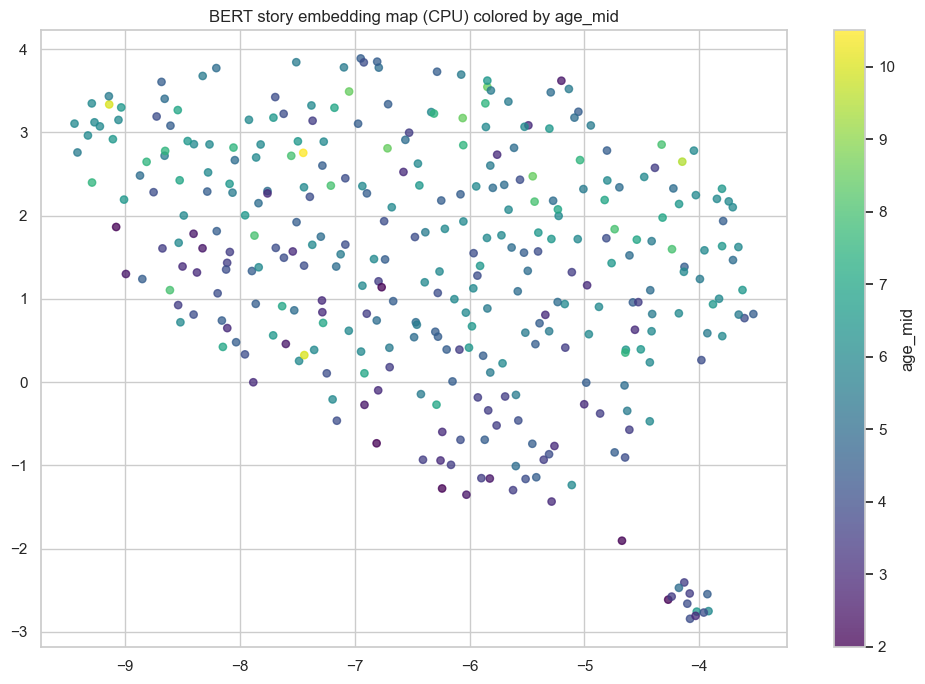

In [20]:
emb_cols = [c for c in bert_df.columns if c.startswith('d')]
X = bert_df[emb_cols].to_numpy(dtype=np.float32)
y = bert_df['age_mid'].to_numpy(dtype=np.float32)
print('X:', X.shape)

xy = embed_2d(X)
plt.figure(figsize=(10,7))
sc = plt.scatter(xy[:,0], xy[:,1], c=y, cmap='viridis', s=28, alpha=0.75)
plt.colorbar(sc, label='age_mid')
plt.title('BERT story embedding map (CPU) colored by age_mid')
plt.tight_layout()


CV corr(pred,age)= 0.25757820876882054 MAE= 1.4404242983809463


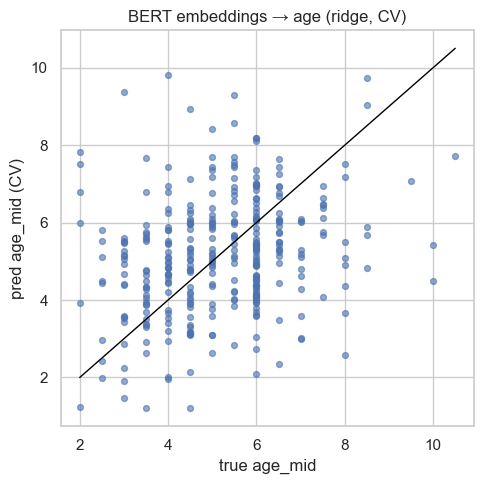

In [21]:
from sklearn.model_selection import KFold

# Simple CV to see if embeddings carry age signal (continuous)
kf = KFold(n_splits=5, shuffle=True, random_state=0)
pred = np.zeros_like(y, dtype=np.float64)
for tr, te in kf.split(X):
    sc = StandardScaler()
    Xtr = sc.fit_transform(X[tr])
    Xte = sc.transform(X[te])
    rr = Ridge(alpha=10.0, random_state=0)
    rr.fit(Xtr, y[tr])
    pred[te] = rr.predict(Xte)

r = np.corrcoef(pred, y)[0,1]
mae = float(np.mean(np.abs(pred - y)))
print('CV corr(pred,age)=', float(r), 'MAE=', mae)

plt.figure(figsize=(5,5))
plt.scatter(y, pred, s=18, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='black', lw=1)
plt.xlabel('true age_mid')
plt.ylabel('pred age_mid (CV)')
plt.title('BERT embeddings → age (ridge, CV)')
plt.tight_layout()


## Distinctive vocabulary by age bin (log-odds)

We compute a simple smoothed log-odds score for each lemma: how characteristic it is of one age bin vs the rest.


In [22]:
meta = pd.DataFrame(sent_meta)
meta['sent_i'] = np.arange(len(meta))

def count_tokens_for_bin(bin_name: str) -> Counter:
    idx = meta.index[meta['age_bin'] == bin_name].tolist()
    c = Counter()
    for i in idx:
        c.update(sentences[i])
    return c


bins = ['0-3','4-6','7-12']
counts = {b: count_tokens_for_bin(b) for b in bins}
N = {b: sum(counts[b].values()) for b in bins}
V = len(w2v.wv)
alpha = 0.01

def log_odds(word: str, b: str) -> float:
    c_in = counts[b].get(word, 0)
    c_out = sum(counts[bb].get(word, 0) for bb in bins if bb != b)
    n_in = N[b]
    n_out = sum(N[bb] for bb in bins if bb != b)
    p_in = (c_in + alpha) / (n_in + alpha * V)
    p_out = (c_out + alpha) / (n_out + alpha * V)
    return math.log(p_in) - math.log(p_out)


rows=[]
for b in bins:
    for w in w2v.wv.index_to_key:
        rows.append({'age_bin': b, 'word': w, 'log_odds': log_odds(w, b), 'aoa': aoa.get(w, np.nan)})
lod = pd.DataFrame(rows)
lod.sort_values(['age_bin','log_odds'], ascending=[True, False]).groupby('age_bin').head(10)


,age_bin,word,log_odds,aoa
789,0-3,stellaluna,10.970869,NaN
829,0-3,miguel,10.923252,NaN
879,0-3,mulligan,10.847286,NaN
984,0-3,anne,10.706247,NaN
1163,0-3,nanette,10.505644,NaN
1187,0-3,guji,10.467918,NaN
1318,0-3,peter,10.345365,NaN
1991,0-3,krack,9.775155,NaN
2017,0-3,mcgregor,9.775155,NaN
2213,0-3,donut,9.608240,5.420000


## Cluster “concepts” within each age bin

Take the top distinctive words for each bin, embed them with Word2Vec, cluster (KMeans), and inspect word lists + mean AoA per cluster.


In [23]:
from sklearn.cluster import KMeans

def bin_concept_clusters(bin_name: str, topn: int = 250, k: int = 8):
    d = lod[lod['age_bin'] == bin_name].sort_values('log_odds', ascending=False).head(topn)
    words = [w for w in d['word'].tolist() if w in w2v.wv]
    X = np.vstack([w2v.wv[w] for w in words])
    km = KMeans(n_clusters=k, random_state=0, n_init='auto')
    lab = km.fit_predict(X)
    out = pd.DataFrame({'age_bin': bin_name, 'word': words, 'cluster': lab})
    out['aoa'] = out['word'].map(lambda w: aoa.get(w, np.nan))
    out['log_odds'] = out['word'].map(lambda w: float(lod[(lod['age_bin']==bin_name)&(lod['word']==w)]['log_odds'].iloc[0]))
    return out, km


clusters_03, km_03 = bin_concept_clusters('0-3', topn=250, k=8)
clusters_46, km_46 = bin_concept_clusters('4-6', topn=250, k=10)
clusters_712, km_712 = bin_concept_clusters('7-12', topn=250, k=10)

clusters = pd.concat([clusters_03, clusters_46, clusters_712], ignore_index=True)
clusters.head()


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


,age_bin,word,cluster,aoa,log_odds
0,0-3,stellaluna,7,NaN,10.970869
1,0-3,miguel,1,NaN,10.923252
2,0-3,mulligan,4,NaN,10.847286
3,0-3,anne,4,NaN,10.706247
4,0-3,nanette,7,NaN,10.505644


In [24]:
def summarize_clusters(df: pd.DataFrame, max_words: int = 12) -> pd.DataFrame:
    rows=[]
    for (b,c), g in df.groupby(['age_bin','cluster']):
        g2 = g.sort_values('log_odds', ascending=False)
        rows.append({
            'age_bin': b,
            'cluster': c,
            'n_words': len(g2),
            'mean_aoa': float(np.nanmean(g2['aoa'].to_numpy())),
            'top_words': ', '.join(g2['word'].head(max_words).tolist()),
        })
    return pd.DataFrame(rows).sort_values(['age_bin','cluster'])


summary = summarize_clusters(clusters, max_words=14)
summary


,age_bin,cluster,n_words,mean_aoa,top_words
0,0-3,0,14,4.706374,"moo, hog, puppy, woof, neigh, crocodile, fat, ..."
1,0-3,1,54,6.213048,"miguel, abuelita, ernesto, imelda, popperville..."
2,0-3,2,39,6.010282,"gruffalo', swap, numero, unles, pup, giraffe, ..."
3,0-3,3,40,6.232283,"humpback, whale, snail, engine, dogs, crab, ba..."
4,0-3,4,11,5.767788,"mulligan, anne, cellar, mike, shovel, dug, mar..."
5,0-3,5,63,6.022227,"guji, peter, mcgregor, percy, trixie, clavel, ..."
6,0-3,6,15,6.816955,"donut, boa, constrictor, walru, leopard, zooke..."
7,0-3,7,14,7.598164,"stellaluna, nanette, krack, pip, baguette, fli..."
8,4-6,0,34,9.463333,"katya, bearskin, kay, gretel, swineherd, liang..."
9,4-6,1,58,6.540130,"lotu, georgie, irene, hansel, pearl, jabari, b..."


## 2D map of bin-specific “concept words” (UMAP if available)


/opt/anaconda3/envs/story-features/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


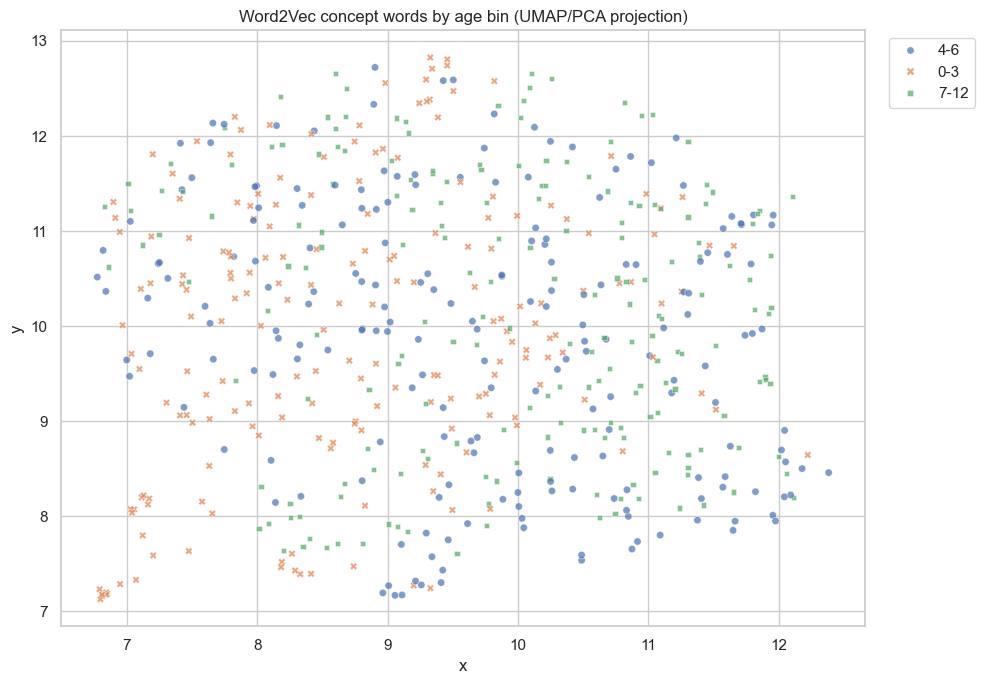

In [25]:
def embed_2d(X: np.ndarray) -> np.ndarray:
    try:
        import umap
        return umap.UMAP(n_neighbors=20, min_dist=0.2, random_state=0).fit_transform(X)
    except Exception:
        from sklearn.decomposition import PCA
        return PCA(n_components=2, random_state=0).fit_transform(X)


plot_df = clusters.copy()
plot_df = plot_df.sample(min(len(plot_df), 600), random_state=0)
X = np.vstack([w2v.wv[w] for w in plot_df['word']])
xy = embed_2d(X)
plot_df['x'] = xy[:,0]
plot_df['y'] = xy[:,1]

plt.figure(figsize=(10,7))
sns.scatterplot(data=plot_df, x='x', y='y', hue='age_bin', style='age_bin', alpha=0.7, s=28)
plt.title('Word2Vec concept words by age bin (UMAP/PCA projection)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()


## Save cluster summary (optional)


In [ ]:
out_dir = Path('artifacts/aoa_word2vec')
out_dir.mkdir(parents=True, exist_ok=True)
summary_path = out_dir / 'concept_clusters_summary.csv'
words_path = out_dir / 'concept_words_with_clusters.csv'

summary.to_csv(summary_path, index=False)
clusters.to_csv(words_path, index=False)
print('Wrote:', summary_path)
print('Wrote:', words_path)


## Optimal cutoffs via separability search (2-bin and 3-bin)

Instead of fixed quantiles, we **search cutpoints** on the age variable that maximize separability in embedding space.

- 2-bin: choose threshold `t` maximizing centroid distance.
- 3-bin: choose `(t1,t2)` maximizing between-class scatter (centroid separation).

Includes an optional permutation test that re-runs the same search to correct for cherry-picking cutpoints.


In [ ]:
import numpy as np
from itertools import combinations

# Build a (word vector, AoA) dataset from the trained Word2Vec model.
words = [w for w in w2v.wv.index_to_key if w in aoa]
Xz = StandardScaler(with_mean=True, with_std=True).fit_transform(np.vstack([w2v.wv[w] for w in words]).astype(np.float32))
y = np.array([aoa[w] for w in words], dtype=np.float32)
print("words w/ AoA + w2v:", len(words), "AoA range", (float(y.min()), float(y.max())))

def _centroid_sep(X, y_mask_a):
    A = X[y_mask_a]
    B = X[~y_mask_a]
    if len(A)==0 or len(B)==0:
        return -1.0
    return float(np.linalg.norm(A.mean(axis=0) - B.mean(axis=0)))

def best_2bin_cutoff(X, y, min_frac=0.15, n_grid=120):
    y = np.asarray(y)
    lo, hi = np.quantile(y, [min_frac, 1-min_frac])
    ts = np.linspace(lo, hi, n_grid)
    best = (-1.0, None)
    for t in ts:
        m = y <= t
        if m.mean() < min_frac or (1-m.mean()) < min_frac:
            continue
        s = _centroid_sep(X, m)
        if s > best[0]:
            best = (s, float(t))
    return best

def between_scatter_objective(X, y, t1, t2):
    # 3 groups: <=t1, (t1,t2], >t2
    g1 = X[y <= t1]
    g2 = X[(y > t1) & (y <= t2)]
    g3 = X[y > t2]
    groups = [g1,g2,g3]
    if any(len(g)==0 for g in groups):
        return -1.0
    mus = [g.mean(axis=0) for g in groups]
    ns = [len(g) for g in groups]
    mu = (ns[0]*mus[0] + ns[1]*mus[1] + ns[2]*mus[2]) / float(sum(ns))
    # trace of between-class scatter: sum n_k * ||mu_k - mu||^2
    return float(sum(n * np.dot(m-mu, m-mu) for n,m in zip(ns,mus)))

def best_3bin_cutoffs(X, y, min_frac=0.15, grid_n=40):
    y = np.asarray(y)
    qs = np.linspace(min_frac, 1-min_frac, grid_n)
    cands = np.quantile(y, qs)
    best = (-1.0, None, None)
    for i in range(len(cands)):
        for j in range(i+1, len(cands)):
            t1 = float(cands[i]); t2=float(cands[j])
            # min group fraction constraint
            f1 = np.mean(y <= t1)
            f2 = np.mean((y > t1) & (y <= t2))
            f3 = np.mean(y > t2)
            if min(f1,f2,f3) < min_frac:
                continue
            s = between_scatter_objective(X, y, t1, t2)
            if s > best[0]:
                best = (s, t1, t2)
    return best

S2, t = best_2bin_cutoff(Xz, y, min_frac=0.15, n_grid=140)
S3, t1, t2 = best_3bin_cutoffs(Xz, y, min_frac=0.15, grid_n=55)
print("Best 2-bin cutoff:", t, "stat=", S2)
print("Best 3-bin cutoffs:", (t1, t2), "stat=", S3)

DO_PERM = False
B = 200
if DO_PERM:
    rng = np.random.default_rng(0)
    perm2=[]
    perm3=[]
    for _ in range(B):
        yp = rng.permutation(y)
        s2,_t = best_2bin_cutoff(Xz, yp, min_frac=0.15, n_grid=140)
        s3,_a,_b = best_3bin_cutoffs(Xz, yp, min_frac=0.15, grid_n=55)
        perm2.append(s2)
        perm3.append(s3)
    p2 = float(np.mean(np.array(perm2) >= S2))
    p3 = float(np.mean(np.array(perm3) >= S3))
    print("perm p-value 2-bin:", p2)
    print("perm p-value 3-bin:", p3)
